In [1]:

import numpy as np
import matplotlib.pyplot as plt
import pickle as pkl
import os
import glob
import cartopy as cp
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from matplotlib.colors import ListedColormap, BoundaryNorm
#from plot_ACCLIP_profs import plot_model_overlay, get_ACCLIP_merge_data, get_model_prof_data
import plotter_config as pc
import numpy as np
import glob
import os
import netCDF4 as nc4
import pickle as pkl
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import matplotlib.tri as tri
import math
from scipy.interpolate import interp1d
import sim_name_remap as map
import plotter_config as pc


In [2]:

file0 = glob.glob('/glade/derecho/scratch/wsmith/archive/FCnudged_f09.carmats16_cesm2.2_2022_E5-1hr/atm/hist/FC*h0.2022-08*')[0]
file1 = glob.glob('/glade/derecho/scratch/wsmith/archive/FCnudged_f09.carmats16_cesm2.2_2022_M2-3hr_rlx-4h/atm/hist/FC*h0.2022-08*')[0]
###file1 = glob.glob('/glade/derecho/scratch/wsmith/archive/FCnudged_f09.carmats16_cesm2.2_2022_M2-3hr/atm/hist/FC*h0.2022-08*')[0]

#file0 = glob.glob('/glade/derecho/scratch/wsmith/archive/FCnudged_f09.carmats16_cesm2.2_2022_E5-1hr/atm/hist/FC*h1.2022-08-18*')[0]
#file1 = glob.glob('/glade/derecho/scratch/wsmith/archive/FCnudged_f09.carmats16_cesm2.2_2022_M2-3hr_rlx-4h/atm/hist/FC*h1.2022-08-18*')[0]

var_str = 'OH'
#var_str = 'CO'


In [3]:

nc0 = nc4.Dataset(file0)
nc1 = nc4.Dataset(file1)

lon = nc0.variables['lon'][:]
lat = nc0.variables['lat'][:]

var0 = nc0.variables[var_str][:]
var1 = nc1.variables[var_str][:]

print(np.shape(var0))

pdeldry0 = nc0.variables['PDELDRY'][:]
pdeldry1 = nc1.variables['PDELDRY'][:]

N_air0 = pdeldry0*6.02E23/(9.81*2.9E-4)  # This formula provided by ChatGPT
N_air1 = pdeldry1*6.02E23/(9.81*2.9E-4)  # This formula provided by ChatGPT

Nvar0 = var0*N_air0
Nvar1 = var1*N_air1

print(np.shape(Nvar0))

var0_col = np.mean(np.sum(Nvar0, axis=1), axis=0)
var1_col = np.mean(np.sum(Nvar1, axis=1), axis=0)

print(np.min(var0_col), np.max(var0_col))

with open('/glade/u/home/wsmith/NudgeComparison_scripts/vars/X' + var_str + '1.pkl', 'wb') as f:
    pkl.dump((lon,lat,var0_col),f)

with open('/glade/u/home/wsmith/NudgeComparison_scripts/vars/X' + var_str + '2.pkl', 'wb') as f:
    pkl.dump((lon,lat,var1_col),f)

print(np.shape(var0_col))


(1, 32, 192, 288)
(1, 32, 192, 288)
69470406359708.93 1.9370650359683203e+19
(192, 288)


Text(0.5, 1.0, 'Column OH percent difference, August 2022')

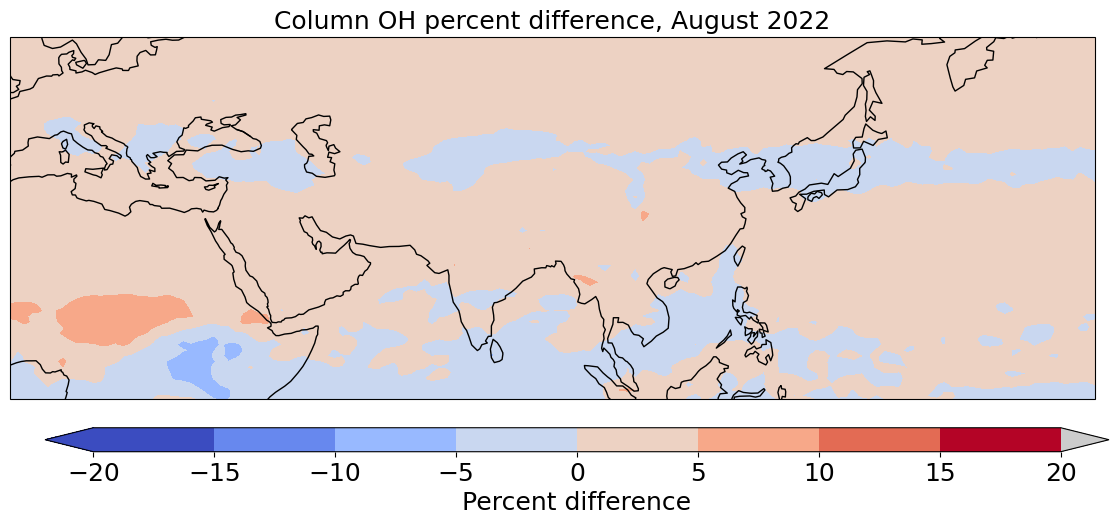

In [4]:

fig = plt.figure(figsize=(14,12))
ax = fig.add_subplot(111, projection = ccrs.PlateCarree())

var_diff = (var0_col - var1_col)*100./var0_col   # Percent change

levels = np.arange(-20,20.1,5)   
colormap = plt.get_cmap('coolwarm')
colormap.set_over([0.8,0.8,0.8])
norm = BoundaryNorm(levels, colormap.N)

con = ax.contourf(lon, lat, var_diff, cmap = colormap, levels = levels, norm=norm, extend = 'both', transform=ccrs.PlateCarree())

ax.set_xlim([0,180])
ax.set_ylim([0,60])

cbaraxes = [0.15,0.30,0.76,0.02]
cbaxes = fig.add_axes(cbaraxes)
cbar = plt.colorbar(con, cax=cbaxes, \
        orientation='horizontal', spacing='uniform',\
        shrink=0.5, extend='both')#, ticks=levels[:-1])  
cbar.ax.tick_params(labelsize=18)
cbar.set_label('Percent difference', fontsize=18)

ax.coastlines()
ax.set_title('Column ' + var_str + ' percent difference, August 2022', fontsize=18)


Text(0.5, 1.0, 'SFISOP percent difference, August 2022')

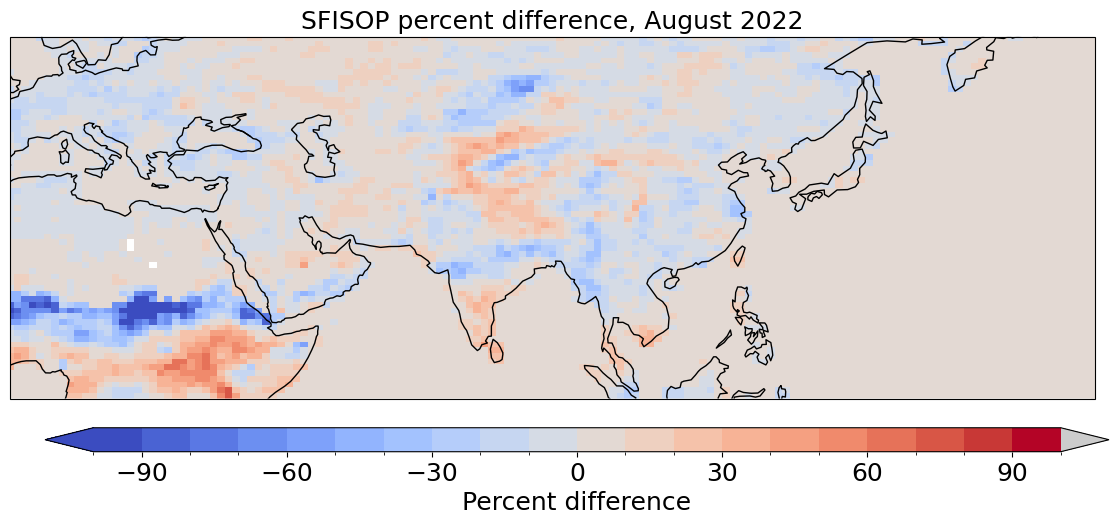

In [5]:

# A third formulation will compare values that are averaged at the surface, with no need for a column adjustment

#var_str = 'LNO_COL_PROD'
var_str = 'SFISOP'

var0 = np.mean(nc0.variables[var_str][:], axis=0)
var1 = np.mean(nc1.variables[var_str][:], axis=0)

fig = plt.figure(figsize=(14,12))
ax = fig.add_subplot(111, projection = ccrs.PlateCarree())

var_diff = (var0 - var1)*100./var0   # Percent change

levels = np.arange(-100,100.1,10)     # Use this for LNO
#levels = np.arange(-50,50.1,10)

colormap = plt.get_cmap('coolwarm')
colormap.set_over([0.8,0.8,0.8])
norm = BoundaryNorm(levels, colormap.N)

#con = ax.contourf(lon, lat, var_diff, cmap = colormap, levels = levels, norm=norm, extend = 'both', transform=ccrs.PlateCarree())
con = ax.pcolormesh(lon, lat, var_diff, cmap=colormap, norm=norm, transform=ccrs.PlateCarree())

ax.set_xlim([0,180])
ax.set_ylim([0,60])

cbaraxes = [0.15,0.30,0.76,0.02]
cbaxes = fig.add_axes(cbaraxes)
cbar = plt.colorbar(con, cax=cbaxes, \
        orientation='horizontal', spacing='uniform',\
        shrink=0.5, extend='both')#, ticks=levels[:-1])  
cbar.ax.tick_params(labelsize=18)
cbar.set_label('Percent difference', fontsize=18)

ax.coastlines()
ax.set_title(var_str + ' percent difference, August 2022', fontsize=18)




In [6]:

# This is a secondary formulation that can be used to calculate column chemical tendencies
# In this case the CHMP variables are in molecules / cm3 / s and we want a total column in molecules / cm2 / s
# To get this we simply multiply by the layer thickness

#var_str = 'CO_CHML'
var_str = 'CO_CHMP'


In [7]:

var0 = np.squeeze(nc0.variables[var_str][:])
var1 = np.squeeze(nc1.variables[var_str][:])

GPH0 = np.squeeze(nc0.variables['Z3'][:])
GPH1 = np.squeeze(nc1.variables['Z3'][:])

var0_col = np.zeros((len(lat), len(lon)))-999
var1_col = np.zeros((len(lat), len(lon)))-999

for lt in range(len(lat)):
    if lt % 50 == 0: print(lt)
    for ln in range(len(lon)):
        curr_col0 = 0
        curr_col1 = 0
        
        for z in range(31):

            curr_col0 = curr_col0 + (GPH0[z,lt,ln] - GPH0[z+1,lt,ln])*100.*var0[z,lt,ln]  # Chemical production column, add recursively
            curr_col1 = curr_col1 + (GPH1[z,lt,ln] - GPH1[z+1,lt,ln])*100.*var1[z,lt,ln]  # Chemical production column, add recursively        

        var0_col[lt,ln] = curr_col0
        var1_col[lt,ln] = curr_col1        

print(np.min(var0_col), np.max(var0_col))
print(np.min(var1_col), np.max(var1_col))


0
50
100
150
5181939.5 1608043855872.0
5152533.0 1643142184960.0


Text(0.5, 1.0, 'Column CO_CHMP percent difference, August 2022')

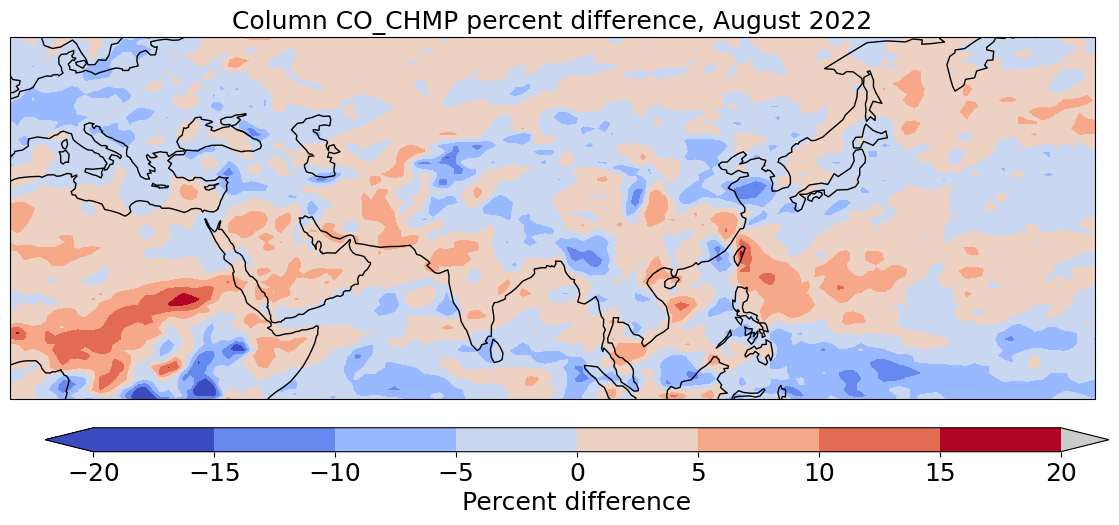

In [8]:

fig = plt.figure(figsize=(14,12))
ax = fig.add_subplot(111, projection = ccrs.PlateCarree())

var_diff = (var0_col - var1_col)*100./var0_col   # Percent change

levels = np.arange(-20,20.1,5)   
colormap = plt.get_cmap('coolwarm')
colormap.set_over([0.8,0.8,0.8])
norm = BoundaryNorm(levels, colormap.N)

con = ax.contourf(lon, lat, var_diff, cmap = colormap, levels = levels, norm=norm, extend = 'both', transform=ccrs.PlateCarree())

ax.set_xlim([0,180])
ax.set_ylim([0,60])

cbaraxes = [0.15,0.30,0.76,0.02]
cbaxes = fig.add_axes(cbaraxes)
cbar = plt.colorbar(con, cax=cbaxes, \
        orientation='horizontal', spacing='uniform',\
        shrink=0.5, extend='both')#, ticks=levels[:-1])  
cbar.ax.tick_params(labelsize=18)
cbar.set_label('Percent difference', fontsize=18)

ax.coastlines()
ax.set_title('Column ' + var_str + ' percent difference, August 2022', fontsize=18)
